<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎛️ Command：一个对象同时「改 state + 选下一跳 + 续跑中断」

**一句话定位**：`Command` = 把 **update / goto / resume / graph** 四种指令打包成一个对象；节点、工具、`invoke` 输入都能给图下指令。
> 本机 langgraph 1.2 实测；`Command` 在 `langgraph.types`。

</div>

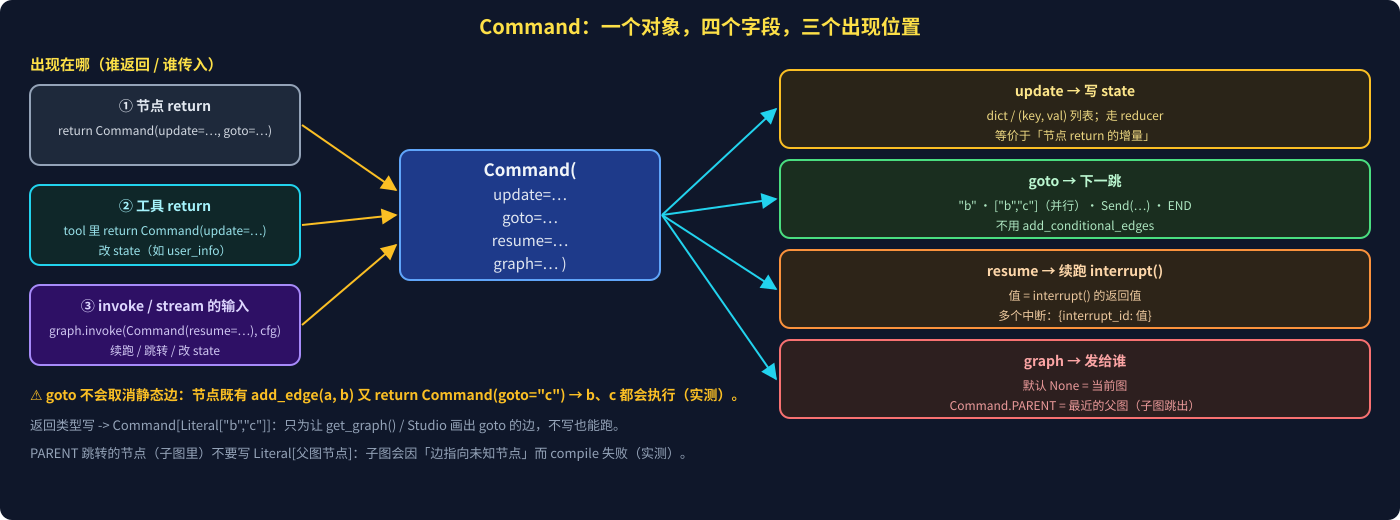

In [ ]:
from IPython.display import SVG
SVG(filename="assets/13_command.svg")

### 1️⃣ 四个字段

| 字段 | 含义 | 取值 |
|---|---|---|
| `update` | 写 state（**走 reducer**，同节点 return 的 dict） | `dict` / `[(key, val)]` |
| `goto` | 下一个节点 | `"b"` · `["b","c"]` 并行 · `Send("b", st)` · `[Send…]` · `END` |
| `resume` | 给 `interrupt()` 的返回值 | 单值 · `{interrupt_id: 值}` |
| `graph` | 发给哪个图 | `None` 当前图 · `Command.PARENT` 父图 |

四个字段**都可选、可任意组合**。

### 2️⃣ 场景 A：节点里「改 state + 路由」合一（最常用）

In [ ]:
from typing import Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command

class State(TypedDict):
    draft: str
    status: str

def score(draft: str) -> float:                                   # 假打分：够长就通过
    return 0.9 if len(draft) > 5 else 0.1

def review(state: State) -> Command[Literal["publish", "rewrite"]]:     # Literal 只是给图/Studio 画边
    ok = score(state["draft"]) > 0.8
    return Command(
        update={"status": "approved" if ok else "rejected"},     # ① 写 state
        goto="publish" if ok else "rewrite",                     # ② 选下一跳
    )

def publish(state: State):
    return {"status": "published"}

def rewrite(state: State):
    return {"draft": state["draft"] + " (longer)"}

builder = StateGraph(State)
builder.add_node("review", review)
builder.add_node("publish", publish)
builder.add_node("rewrite", rewrite)
builder.add_edge(START, "review")           # 不需要 add_conditional_edges，也不需要 review 的出边
builder.add_edge("publish", END)
builder.add_edge("rewrite", END)
graph = builder.compile()

graph.invoke({"draft": "hello world", "status": ""})    # → status: 'published'
graph.invoke({"draft": "hi", "status": ""})             # → draft 变长、status: 'rejected'
# 并行扇出：goto=["a", "b"]；动态 N 个：goto=[Send("worker", {"x": i}) for i in items]

| 对比 | `add_conditional_edges(路由函数)` | `Command(goto=…)` |
|---|---|---|
| 路由函数能写 state？ | ❌ 只能返回节点名 | ✅ 同一处 `update` + `goto` |
| 路由逻辑放哪 | 节点外（边上） | 节点内（和业务逻辑一起） |
| 适合 | 纯判断（`tools_condition`） | 做完事再决定去哪 / 多 agent handoff |

### 2️⃣➕ 远距离跳转：`goto` 可直达图中任意节点

In [ ]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command

class State(TypedDict):
    log: Annotated[list, operator.add]

def node(name):
    return lambda state: {"log": [name]}

def a(state: State):
    return Command(update={"log": ["a"]}, goto="z")      # 不写 Literal 注解，a 也没有出边

builder = StateGraph(State)
builder.add_node("a", a)
for name in ["m", "z"]:
    builder.add_node(name, node(name))
builder.add_edge(START, "a")
builder.add_edge("z", END)
builder.compile().invoke({"log": []})                    # → ['a', 'z']：m 完全没跑

| 要点（均已实测） | |
|---|---|
| 范围 | 同一个图里任何 `add_node` 过的节点，**不需要**两点之间有路径 |
| 跨图 | 子图 → 父图：`Command(graph=Command.PARENT, goto="父图节点")`；不能直接进别的子图内部，只能跳到该子图节点 |
| 向后跳 | `goto="a"` 回到前面 = 循环，要加终止条件，否则撞默认 25 步 `GraphRecursionError` |
| 名字写错 | **不报错**，只打日志 `wrote to unknown channel branch:to:xxx, ignoring it`，该次跳转被忽略 |
| 静态边 | 仍然照走：若 `a` 另有 `a→b→…→z` 静态边，`goto="z"` 之外 `b…` 也会跑，`z` 可能执行两次 |
| `Literal` 注解 | 只影响 `get_graph()` / Studio 画边，不影响能否跳转 |

### 3️⃣ 场景 B：配合 `interrupt()` 续跑（HITL）

In [ ]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt

class State(TypedDict):
    log: Annotated[list, operator.add]

def ask(state: State):
    answer = interrupt({"question": "继续吗？"})     # 节点内：暂停，answer 是下面 resume 的值
    return {"log": [f"answer={answer}"]}

graph = (StateGraph(State).add_node("ask", ask)
         .add_edge(START, "ask").add_edge("ask", END)
         .compile(checkpointer=InMemorySaver()))     # resume 必须有 checkpointer
cfg = {"configurable": {"thread_id": "1"}}
inputs = {"log": []}

graph.invoke(inputs, cfg)                           # → 返回 {"__interrupt__": [Interrupt(value=…, id=…)]}
graph.invoke(Command(resume="yes"), cfg)            # 同 thread_id 续跑；节点从头重跑，interrupt() 返回 "yes"
# 并行分支多个中断：Command(resume={"id1": "A", "id2": "B"}) 按 interrupt id 一次性恢复
# resume 可同时带 update（实测先写 state 再续跑）：Command(resume="yes", update={...})

### 4️⃣ 场景 C：作为 `invoke` 输入「跳转 / 改 state」

```python
graph.invoke({"x": 1}, cfg)                                         # 先跑完一轮
graph.invoke(Command(update={"log": ["X"]}, goto="c"), cfg)         # 对同 thread：先写 state，再从 c 开始跑
```
实测：第二次从 `c` 开始，`update` 先经过 reducer。适合「外部事件要求从某节点重来」。

### 5️⃣ 场景 D：子图里「跳出」到父图

```python
def sub_node(state):                                        # 在子图节点内
    return Command(graph=Command.PARENT,                    # 目标：最近的父图
                   update={"log": ["from_sub"]},            # update 的 key 必须是父图 state 里有的
                   goto="c")                                # c 是父图节点
```
| 要点 | |
|---|---|
| 典型用途 | 多 agent **handoff**：子 agent 决定交给父图里的另一个 agent |
| 返回注解 | 子图里**不要**写 `Command[Literal["父图节点"]]`，否则子图 compile 报 `Found edge ending at unknown node` |
| 父图边 | 父图若同时有 `sub → b` 静态边，`b` 和 `c` **都会跑**（实测） |

### 6️⃣ 场景 E：工具返回 Command——工具改 state

```python
from langchain_core.tools import tool, InjectedToolCallId
from langchain_core.messages import ToolMessage
from typing import Annotated

@tool
def login(name: str, tool_call_id: Annotated[str, InjectedToolCallId]) -> Command:
    """登录并记住用户名"""
    return Command(update={
        "user": name,                                                           # 工具直接改 state
        "messages": [ToolMessage(f"hi {name}", tool_call_id=tool_call_id)],     # ⚠️ 必须回一条 ToolMessage，否则下次调模型报错
    })
# ToolNode([login]) 执行后：state["user"] == "Lance"（实测）
```
`InjectedToolCallId` 让 LLM 看不到该参数，由 ToolNode 注入；`ToolMessage.tool_call_id` 必须与请求配对（见笔记 02）。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**踩坑清单（均已实测）**

| 坑 | 结果 |
|---|---|
| 节点有静态边 `add_edge(a,b)` 又 `Command(goto="c")` | **b、c 都执行**；`goto` 是"追加"不是"替换" |
| `goto=END` 想提前结束，但节点有静态出边 | 静态边照走（实测 `b` 仍执行）——要提前结束就别给该节点加静态出边 |
| `Command(resume=…)` 但图没挂 checkpointer | `RuntimeError: Cannot use Command(resume=...) without checkpointer` |
| `Command(update=…)` 当输入传给「已结束」的图 | 会"卡住"，续聊用普通 input |
| 工具 `Command` 不带 `ToolMessage` | 下一次调用模型报 tool_call 无响应 |
| 不写 `-> Command[Literal[…]]` | 能跑，但 `get_graph()` / Studio 看不到 goto 的边 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`Command` = **update（写 state）+ goto（下一跳）+ resume（续跑 interrupt）+ graph（给谁）**；节点 return、工具 return、`invoke` 输入三处都能用；记住 **goto 不取消静态边**、**工具 Command 必带 ToolMessage**、**子图用 `Command.PARENT` 跳父图**。

</div>